# Examen 2 | Modelo de Varianza: EWMA — GMEXICOB

Aplicamos el modelo EWMA (Exponentially Weighted Moving Average / RiskMetrics)
al precio de Grupo México (GMEXICOB), usando los mismos últimos 2 años de
datos que el modelo de media móvil, y probando los dos valores de λ que
recomienda J.P. Morgan (0.94 y 0.97) para encontrar cuál pronostica mejor.

## El modelo

A diferencia de la media móvil (que pesa todos los días por igual dentro de
una ventana), EWMA le da **más peso a los datos recientes** y ese peso
decae exponencialmente a una tasa $\lambda$ (factor de decaimiento):

$$\sigma^2_t = \sum_{i=0}^{\infty} (1-\lambda)\,\lambda^{i}\, R^2_{t-1-i}$$

Desarrollando esta suma y aprovechando su recursividad, se simplifica al
**modelo RiskMetrics** (J.P. Morgan, 1994):

$$\sigma^2_t = (1-\lambda)\,R^2_{t-1} + \lambda\,\sigma^2_{t-1}$$

La varianza de hoy es una mezcla de dos cosas: **lo nuevo** (el retorno de
ayer, con peso $1-\lambda$) y **lo que ya sabíamos** (la varianza estimada
de ayer, con peso $\lambda$). J.P. Morgan determinó que $\lambda$ suele
estar entre 0.94 y 0.97, según la periodicidad de los datos — por eso
probamos ambos.

In [1]:
import sys, os

SRC_PATH = os.path.abspath(os.path.join(os.getcwd(), "..", "src"))
sys.path.append(SRC_PATH)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from calculo_rendimientos import calculate_returns

GMEXICO_PATH = os.path.join("..", "datos_historicos", "gmexico_prices.csv")

## Datos: últimos 2 años de GMEXICOB

Mismo rango y misma fuente que el modelo de media móvil, para que los
resultados de los 3 modelos del equipo sean comparables en el póster.

In [2]:
df_gmexico = calculate_returns(GMEXICO_PATH)

fecha_fin = df_gmexico.index.max()
fecha_inicio = fecha_fin - pd.DateOffset(years=2)
df_2y = df_gmexico.loc[fecha_inicio:].copy()

print(f"Periodo: {df_2y.index.min().date()} a {df_2y.index.max().date()}")
print(f"Total de dias habiles: {len(df_2y)}")
df_2y.tail()

Periodo: 2024-09-17 a 2026-09-14
Total de dias habiles: 499


,adj_close,simple_return,log_return,cumulative_return
Date,,,,
2026-09-08,229.559998,0.025875,0.025546,116.658060
2026-09-09,228.500000,-0.004618,-0.004628,116.119389
2026-09-10,218.339996,-0.044464,-0.045483,110.956267
2026-09-11,218.300003,-0.000183,-0.000183,110.935943
2026-09-14,213.910004,-0.020110,-0.020315,108.705029


## $R^2$: proxy de la varianza real de cada día

Igual que en media móvil, usamos el retorno logarítmico diario al
cuadrado ($R^2$) como aproximación de la varianza "real" observada.

In [3]:
r = df_2y['log_return']
r2 = r**2
r2.tail()

Date
2026-09-08    6.525810e-04
2026-09-09    2.142035e-05
2026-09-10    2.068680e-03
2026-09-11    3.355731e-08
2026-09-14    4.126949e-04
Name: log_return, dtype: float64

## Calculando $\sigma^2_t$ con la fórmula recursiva

Usamos `.shift(1)` sobre $R^2$ y luego `.ewm(alpha=1-\lambda, adjust=False)`
de pandas — esto reproduce exactamente la fórmula recursiva de RiskMetrics,
calculando $\sigma^2_t$ solo con información hasta $t-1$ (es un pronóstico,
igual que en media móvil). Probamos $\lambda = 0.94$ y $\lambda = 0.97$.

`.ewm(alpha=..., adjust=False)` es la función de pandas para medias móviles
con pesos exponenciales — `alpha` es el peso que le da al dato nuevo en
cada paso, por eso usamos `alpha = 1 - lambda` (el peso de "lo nuevo" en
nuestra fórmula).

In [4]:
lambdas = [0.94, 0.97]

sigma2 = pd.DataFrame(index=r.index)
for lam in lambdas:
    sigma2[f'ewma_{lam}'] = r2.shift(1).ewm(alpha=(1 - lam), adjust=False).mean()

sigma2.tail()

,ewma_0.94,ewma_0.97
Date,,
2026-09-08,0.000385,0.000414
2026-09-09,0.000401,0.000421
2026-09-10,0.000378,0.000409
2026-09-11,0.000480,0.000459
2026-09-14,0.000451,0.000445


## RMSE: ¿cuál λ pronostica mejor?

Mismo criterio que en media móvil: comparamos cada pronóstico $\sigma^2_t$
contra el $R^2_t$ real de ese día. **El $\lambda$ con menor RMSE es el que
mejor pronostica** — es la respuesta lista para "¿por qué ese lambda?" en
la presentación oral.

In [5]:
sigma2_rmse = sigma2.dropna()
r2_rmse = r2.loc[sigma2_rmse.index]

rmse = pd.Series(dtype=float)
for lam in lambdas:
    rmse[f'ewma_{lam}'] = np.sqrt((1/len(r2_rmse)) * ((r2_rmse - sigma2_rmse[f'ewma_{lam}'])**2).sum())

rmse

ewma_0.94    0.001421
ewma_0.97    0.001414
dtype: float64

## Lambda óptimo ($\lambda^*$)

In [6]:
lambda_opt = float(rmse.idxmin().replace('ewma_', ''))
print(f"Lambda optimo (menor RMSE): lambda* = {lambda_opt}")
rmse

Lambda optimo (menor RMSE): lambda* = 0.97


ewma_0.94    0.001421
ewma_0.97    0.001414
dtype: float64

## Pronóstico de volatilidad para mañana

Con $\lambda^*$, aplicamos la fórmula recursiva una vez más usando el
$\sigma^2$ de hoy y el $R^2$ de hoy, para obtener el pronóstico de mañana:

$$\sigma^2_{T+1} = (1-\lambda^*)\,R^2_T + \lambda^*\,\sigma^2_T$$

In [7]:
sigma2_hoy = sigma2[f'ewma_{lambda_opt}'].iloc[-1]
r2_hoy = r2.iloc[-1]

var_manana = lambda_opt * sigma2_hoy + (1 - lambda_opt) * r2_hoy
vol_anual_manana = np.sqrt(252 * var_manana)

print(f"Varianza pronosticada para manana (lambda*={lambda_opt}): {var_manana:.6f}")
print(f"Volatilidad anualizada pronosticada: {vol_anual_manana:.2%}")

Varianza pronosticada para manana (lambda*=0.97): 0.000444
Volatilidad anualizada pronosticada: 33.45%


## Verificación contra la volatilidad histórica simple

Como chequeo de sanidad (igual que la celda "σ hist excel" de la hoja de
cálculo de clase), comparamos contra la desviación estándar simple de
todos los retornos del período — sin pesos, todos los días cuentan igual.
Si el número de EWMA está en un rango parecido, nos da confianza de que el
cálculo está bien.

In [8]:
vol_hist_diaria = r.std()
vol_hist_anual = vol_hist_diaria * np.sqrt(252)

print(f"Volatilidad historica simple (toda la muestra, anualizada): {vol_hist_anual:.2%}")
print(f"Volatilidad EWMA pronosticada (lambda*={lambda_opt}): {vol_anual_manana:.2%}")

Volatilidad historica simple (toda la muestra, anualizada): 35.46%
Volatilidad EWMA pronosticada (lambda*=0.97): 33.45%


## Gráfica: volatilidad EWMA anualizada por λ

Visualizamos ambos valores de $\lambda$ en el tiempo — $\lambda=0.94$
reacciona un poco más rápido a los cambios recientes; $\lambda=0.97$ es
ligeramente más suave/estable (le da más memoria al pasado).

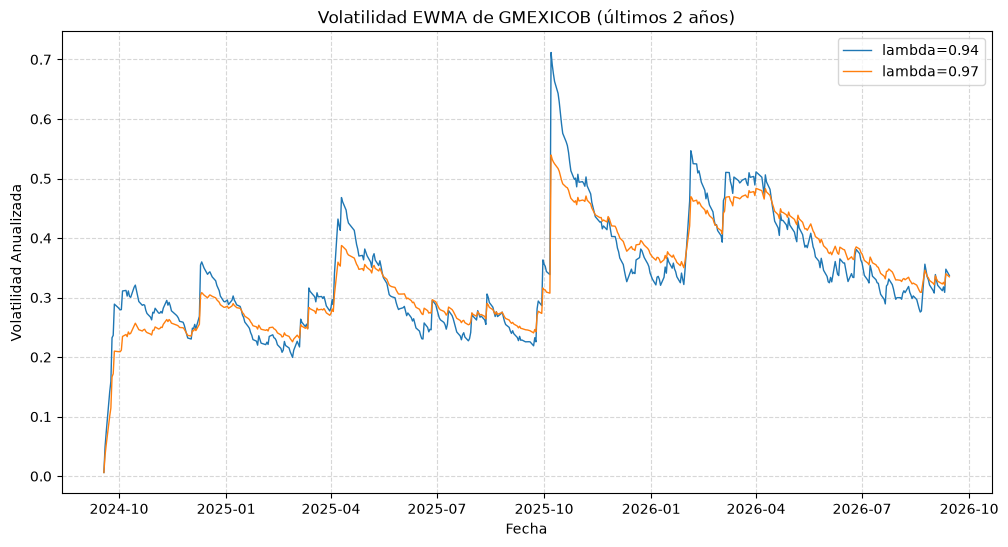

In [9]:
fig, ax = plt.subplots(figsize=(12, 6))

for lam in lambdas:
    vol_anual = np.sqrt(sigma2[f'ewma_{lam}'] * 252)
    ax.plot(sigma2.index, vol_anual, label=f'lambda={lam}', linewidth=1)

ax.set_xlabel('Fecha')
ax.set_ylabel('Volatilidad Anualizada')
ax.set_title('Volatilidad EWMA de GMEXICOB (últimos 2 años)')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)

save_path = os.path.join("..", "graficas", "ewma_volatilidad.png")
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()